# Day 1–2 — Data Inspection and Exploratory Data Analysis

This notebook inspects the Telco Customer Churn dataset, investigates data quality, explores relationships with churn, and documents initial feature decisions.

## 1. Load and Inspect the Dataset

Load the CSV and inspect its dimensions, schema, missing values, duplicate rows, and column names.

In [1]:
import pandas as pd
df = pd.read_csv("../data/telco-customer-churn.csv")

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.isnull().sum().sort_values(ascending=False)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.columns.to_list()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

## 2. Data Quality: Investigating `TotalCharges`

The source column is stored as text. First inspect its values and identify whitespace-only entries before converting it to numeric.

In [8]:
df["TotalCharges"].value_counts().head(10)

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
19.65     8
45.3      7
19.55     7
20.15     6
19.45     6
Name: count, dtype: int64

In [9]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [10]:
df.loc[df["TotalCharges"].str.strip().eq(""),["tenure", "MonthlyCharges", "Churn"]]

,tenure,MonthlyCharges,Churn
488,0,52.55,No
753,0,20.25,No
936,0,80.85,No
1082,0,25.75,No
1340,0,56.05,No
3331,0,19.85,No
3826,0,25.35,No
4380,0,20.00,No
5218,0,19.70,No
6670,0,73.35,No


In [11]:
df.loc[df["tenure"].eq(0),["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [12]:
df.loc[df["tenure"].eq(0),"TotalCharges"].value_counts()

TotalCharges
    11
Name: count, dtype: int64

### Clean `TotalCharges`

The 11 blank values occur for customers with zero tenure. For this exploratory analysis, treat those blank charges as zero. This is an assumption to document and validate against the dataset definition.

In [13]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", pd.NA),errors="raise")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [14]:
df["TotalCharges"].dtype

dtype('float64')

In [15]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [16]:
df.loc[df["tenure"].eq(0), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


## 3. Target Variable: Churn Distribution

Inspect the class counts and class percentages. This establishes the baseline class balance for later model evaluation.

In [17]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [18]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## 4. Numerical Feature Summary

Summarize the distributions of tenure, monthly charges, and total charges after cleaning `TotalCharges`.

In [19]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


## 5. Contract and Churn

Compare churn proportions across contract types. These are observed associations, not evidence that contract type alone causes churn.

In [20]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [21]:
df.groupby(
    ["Contract", "Churn"]
)["tenure"].mean().round(2)

Contract        Churn
Month-to-month  No       21.03
                Yes      14.02
One year        No       41.67
                Yes      44.96
Two year        No       56.60
                Yes      61.27
Name: tenure, dtype: float64

In [22]:
pd.crosstab(
    df["Contract"],
    df["Churn"]
)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


## 6. Numerical Features by Churn

Compare numeric feature distributions across the two target classes using summary statistics and boxplots.

In [23]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


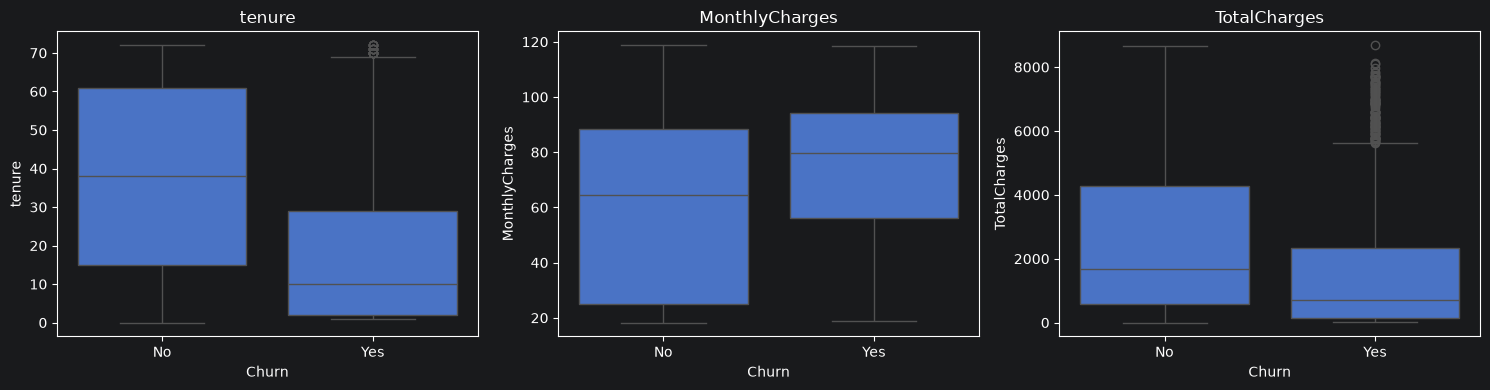

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

features = ["tenure", "MonthlyCharges", "TotalCharges"]

for ax, feature in zip(axes, features):
    sns.boxplot(data=df, x="Churn", y=feature, ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

## 7. Internet Service and Churn

Compare churn rates and customer characteristics across internet-service categories.

In [25]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [26]:
df.groupby("InternetService")[
    ["MonthlyCharges", "tenure"]
].mean().round(2)

,MonthlyCharges,tenure
InternetService,,
DSL,58.10,32.82
Fiber optic,91.50,32.92
No,21.08,30.55


In [27]:
df.groupby(
    ["InternetService", "Churn"]
)[["MonthlyCharges", "tenure"]].mean().round(2)

MonthlyCharges  tenure
InternetService Churn                        
DSL             No              60.21   37.20
                Yes             49.08   14.11
Fiber optic     No              93.93   42.09
                Yes             88.13   20.20
No              No              21.14   32.33
                Yes             20.37    8.24

## 8. Payment Method and Churn

Inspect churn rates by payment method, then examine how payment methods are distributed across contract types.

In [28]:
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [29]:
pd.crosstab(
    df["PaymentMethod"],
    df["Contract"],
    normalize="index"
).mul(100).round(2)

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),38.15,25.32,36.53
Credit card (automatic),35.68,26.15,38.17
Electronic check,78.22,14.67,7.10
Mailed check,55.40,20.91,23.70


In [30]:
pd.crosstab(
    [df["Contract"], df["PaymentMethod"]],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn                                        No    Yes
Contract       PaymentMethod                          
Month-to-month Bank transfer (automatic)  65.87  34.13
               Credit card (automatic)    67.22  32.78
               Electronic check           46.27  53.73
               Mailed check               68.42  31.58
One year       Bank transfer (automatic)  90.28   9.72
               Credit card (automatic)    89.70  10.30
               Electronic check           81.56  18.44
               Mailed check               93.18   6.82
Two year       Bank transfer (automatic)  96.63   3.37
               Credit card (automatic)    97.76   2.24
               Electronic check           92.26   7.74
               Mailed check               99.21   0.79

## 9. Online Security and Tech Support

Explore associations between these service features and churn, and examine how often the two features co-occur.

In [31]:
pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


In [32]:
df.groupby(
    "OnlineSecurity"
)[["MonthlyCharges", "tenure"]].mean().round(2)

,MonthlyCharges,tenure
OnlineSecurity,,
No,75.69,25.85
No internet service,21.08,30.55
Yes,78.84,45.05


In [33]:
pd.crosstab(
    [df["OnlineSecurity"], df["Contract"]],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn                                  No    Yes
OnlineSecurity      Contract                    
No                  Month-to-month  48.95  51.05
                    One year        82.59  17.41
                    Two year        93.23   6.77
No internet service Month-to-month  81.11  18.89
                    One year        97.53   2.47
                    Two year        99.22   0.78
Yes                 Month-to-month  70.42  29.58
                    One year        89.13  10.87
                    Two year        97.05   2.95

In [34]:
pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


In [35]:
pd.crosstab(
    df["OnlineSecurity"],
    df["TechSupport"],
    normalize="index"
).mul(100).round(2)

TechSupport,No,No internet service,Yes
OnlineSecurity,,,
No,72.98,0.0,27.02
No internet service,0.00,100.0,0.00
Yes,45.57,0.0,54.43


## 10. Paperless Billing and Payment Method

Compare churn rates by billing preference and payment method. These cross-tabs can reveal associations but do not establish causality.

In [36]:
pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


In [37]:
pd.crosstab(
    df["PaperlessBilling"],
    df["PaymentMethod"],
    normalize="index"
).mul(100).round(2)

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
PaperlessBilling,,,,
No,22.74,22.28,21.69,33.29
Yes,21.36,21.15,41.76,15.73


In [38]:
pd.crosstab(
    [df["PaymentMethod"], df["PaperlessBilling"]],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn                                          No    Yes
PaymentMethod             PaperlessBilling              
Bank transfer (automatic) No                88.97  11.03
                          Yes               79.12  20.88
Credit card (automatic)   No                90.00  10.00
                          Yes               80.95  19.05
Electronic check          No                67.26  32.74
                          Yes               50.23  49.77
Mailed check              No                86.51  13.49
                          Yes               72.71  27.29

## 11. Dependents and Partner Status

Compare churn rates by household-related features and inspect the relationship between partner and dependent status.

In [39]:
pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


In [40]:
pd.crosstab(
    [df["Dependents"], df["Contract"]],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn                         No    Yes
Dependents Contract                    
No         Month-to-month  54.76  45.24
           One year        87.58  12.42
           Two year        96.69   3.31
Yes        Month-to-month  67.17  32.83
           One year        90.77   9.23
           Two year        97.72   2.28

In [41]:
pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


In [42]:
pd.crosstab(
    df["Partner"],
    df["Dependents"],
    normalize="index"
).mul(100).round(2)

Dependents,No,Yes
Partner,,
No,90.09,9.91
Yes,48.59,51.41


## 12. Final Data-Type and Integrity Checks

Confirm the final schema, the binary encoding of `SeniorCitizen`, missing-value count, duplicate-row count, customer-ID uniqueness, and target labels.

In [43]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [44]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [45]:
print(df["SeniorCitizen"].value_counts(dropna=False))
print("Unique values:", df["SeniorCitizen"].unique())

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
Unique values: [0 1]


In [46]:
# Check missing values
print("Missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check unique customer IDs
print("Unique customer IDs:", df["customerID"].nunique())

# Check target labels
print(df["Churn"].value_counts())

# Check target values
print("Target categories:", df["Churn"].unique())

Missing values: 0
Duplicate rows: 0
Unique customer IDs: 7043
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Target categories: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


## 13. Feature Selection — Initial Audit

**Prediction objective:** Predict whether a customer is likely to churn using information available at the time of prediction.

**Excluded from model inputs**
- `customerID`: Identifier retained for record tracking, not used as an initial predictive feature.
- `Churn`: Target variable; used to construct `y`, never included in `X`.

**Candidate features**
- Customer characteristics: `gender`, `SeniorCitizen`, `Partner`, `Dependents`
- Customer relationship: `tenure`
- Services: `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`
- Contract and billing: `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`

**Important assumptions and checks**
- Blank `TotalCharges` values were converted to zero for zero-tenure customers. Validate this assumption against the dataset definition.
- Associations found during EDA do not establish causation.
- Feature usefulness will be evaluated through controlled model evaluation.
- Preprocessing must be fitted on training data only to avoid leakage from validation/test data.

## 14. Day 1–2 Summary and Next Steps

### EDA conclusions
- The target is imbalanced: approximately 73.46% of customers did not churn and 26.54% did.
- Month-to-month contracts have substantially higher observed churn rates than longer contracts.
- Higher churn rates were observed among electronic-check customers and customers without online security or technical support.
- These are associations, not causal claims or proof of model performance.

### Candidate features
All 19 columns other than `customerID` and `Churn` are candidates for the initial model. Keep related features initially and evaluate their predictive contribution rather than assuming redundancy.

### Important modeling caveat
Use `TotalCharges` only if it represents charges accumulated by the prediction timestamp. The correct feature set depends on when the business intends to make churn predictions.

### Next phase
Define the prediction target, split the data, build preprocessing pipelines, and establish a baseline Logistic Regression model.